# Extracting expert actions: how the reduced action spaces are built

The agents of this package do not search the whole topology action space of the grid. On `ai4realnet_small`, changing the bus assignment (`set_bus`) of the elements of one substation already gives **66,811** possible actions. The agents use a few hundred actions instead, proposed by the expert system [ExpertOp4Grid](https://github.com/marota/ExpertOp4Grid) ("alphaDeesp").

This notebook explains, step by step, how the two extraction scripts of the package produce these actions:

| Script | What it does |
|---|---|
| [`ExpertAgent/utils/extractExpertActions.py`](../ExpertAgent/utils/extractExpertActions.py) | Expert actions for the overloads that happen in **normal operation** |
| [`ExpertAgent/utils/extractAttackingExpertActions.py`](../ExpertAgent/utils/extractAttackingExpertActions.py) | Expert actions for the overloads that happen **after a line is disconnected** (an attack or a contingency) |

Both scripts apply the same procedure to every timestep of every scenario (chronic) of the environment:

1. **Load the grid state** of that timestep.
2. If a line is **overloaded** (`rho > 1`, more current than its thermal limit), run the **expert analysis**. It builds the *overflow graph*, which shows where the flow goes when the overloaded line is relieved. From it, *AlphaDeesp* ranks changes of topology (bus assignments) at the substations that matter.
3. **Simulate** the best candidates and give each one a **score from 0 to 4**.
4. **Keep the actions scoring 3 or 4**, add the new ones to the list, and **save** the list.

The result is a file of action vectors (`.npz`). The agents load it as their action space, as shown in section 8.

**Contents**
1. Configuration of the expert system
2. Loading a grid state with an overload
3. Expert analysis: overflow graph and ranked topologies
4. Simulating and scoring the candidates
5. From the kept actions to the saved files
6. Running `get_expert_actions` on a few timesteps
7. The attacking variant: overloads after a line disconnection
8. How the agents use the extracted actions
9. Running the full extraction from the command line

> **Runtime.** One overloaded state takes about 2 seconds to analyse. This notebook analyses only a few of them and runs in a few minutes. The complete extraction covers 61 scenarios × 2,016 timesteps, and overloads happen at more than half of them. It takes days, so it is run from the command line (section 9).

**Prerequisites:** the ExpertOp4Grid package installed (see the [README](../README.md#expertop4grid-package)), and the `ai4realnet_small` environment in `~/data_grid2op`.

In [1]:
import os
import io
import shutil
import contextlib
import warnings
warnings.filterwarnings("ignore")
from configparser import ConfigParser

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from grid2op.Converter import IdToAct
from alphaDeesp.core.grid2op.Grid2opObservationLoader import Grid2opObservationLoader
from alphaDeesp.core.grid2op.Grid2opSimulation import Grid2opSimulation
from alphaDeesp.core.graphsAndPaths import OverFlowGraph
from alphaDeesp.core.alphadeesp import AlphaDeesp

from ExpertAgent import ASSETS
from ExpertAgent.utils.helper_functions import EncodedTopologyAction, action_symmetry
from ExpertAgent.utils.extractExpertActions import get_expert_actions
from ExpertAgent.utils.extractAttackingExpertActions import get_attacking_expert_actions
from ExpertAgent.utils.local_data import get_local_data_dir

pd.set_option("display.width", 200)


@contextlib.contextmanager
def quiet():
    # ExpertOp4Grid prints a lot of progress messages: hide them to keep the notebook readable.
    with contextlib.redirect_stdout(io.StringIO()):
        yield

2026-11-27 17:02:47.367927: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-27 17:02:47.445694: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-11-27 17:02:48.517904: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Configuration of the expert system

ExpertOp4Grid reads its parameters from [`ExpertAgent/utils/config.ini`](../ExpertAgent/utils/config.ini). The scripts read this file and set `gridPath` to the environment folder, `~/data_grid2op/<env_name>`. The parameters that matter most here:

| Parameter | Meaning |
|---|---|
| `ThresholdReportOfLine` | A line is part of the overflow graph only if its flow changes by more than this share of the overload |
| `ratioToKeepLoop` | Loop paths carrying less than this share of the biggest loop's flow are ignored |
| `maxUnusedLines` | How many unused lines a path may cross |
| `totalNumberOfSimulatedTopos` | How many candidate topologies are simulated in total for one state (30) |
| `numberOfSimulatedToposPerNode` | How many of them at most per substation (10) |

In [2]:
env_name = "ai4realnet_small"
env_path = os.path.join(os.path.expanduser("~"), "data_grid2op", env_name)

import ExpertAgent.utils as expert_utils
config_path = os.path.join(os.path.dirname(expert_utils.__file__), "config.ini")
config = ConfigParser()
config.read(config_path)
config.set("DEFAULT", option="gridPath", value=env_path)   # as the scripts do

for key in ["gridPath", "ThresholdReportOfLine", "ratioToKeepLoop", "maxUnusedLines",
            "totalNumberOfSimulatedTopos", "numberOfSimulatedToposPerNode"]:
    print(f"{key:32s} {config['DEFAULT'][key]}")

gridPath                         /home/milad/data_grid2op/ai4realnet_small
ThresholdReportOfLine            0.2
ratioToKeepLoop                  0.25
maxUnusedLines                   3
totalNumberOfSimulatedTopos      30
numberOfSimulatedToposPerNode    10


## 2. Loading a grid state with an overload

`Grid2opObservationLoader` creates the grid2op environment with the overflow protections switched off. An overloaded line therefore stays connected, and its state can be analysed. `get_observation(chronic_scenario, timestep)` resets the environment to the given scenario and fast-forwards it to the given timestep. It returns the environment, the observation and the action space.

The scripts call it for every timestep. Here we look for the first overload of scenario 4 after timestep 95.

In [3]:
with quiet():
    loader = Grid2opObservationLoader(env_path)

chronic, timestep = 4, None
for ts in range(95, 130):
    with quiet():
        env, obs, action_space = loader.get_observation(chronic_scenario=chronic, timestep=ts)
    if any(obs.rho > 1.):          # the test the scripts make before analysing a state
        timestep = ts
        break

print(f"Grid: {env.n_sub} substations, {env.n_line} lines, {env.max_episode_duration()} timesteps per scenario")
print(f"Scenario {chronic} ({env.chronics_handler.get_name()}), first overload at timestep {timestep}")

ltc = [int(l) for l in np.where(obs.rho > 1)[0]]   # "lines to cut": the overloaded lines to solve
for line in ltc:
    print(f"  line {line} ({env.name_line[line]}) is loaded at {obs.rho[line]:.1%} of its thermal limit")

Grid: 36 substations, 59 lines, 2017 timesteps per scenario
Scenario 4 (2035-01-15_0), first overload at timestep 101
  line 39 (54_58_154) is loaded at 102.0% of its thermal limit


## 3. Expert analysis: overflow graph and ranked topologies

**Grid2opSimulation** prepares the analysis. It simulates the disconnection of the overloaded line(s) `ltc`. This shows how the flow they carry would spread over the rest of the grid: the `delta_flows` column below. The lines whose flow increases most are the paths that would take over the overload. In this table, ExpertOp4Grid names a line `<origin substation>_<extremity substation>_<line id>`, which differs from the grid2op names used elsewhere (`env.name_line`). The line id at the end is the same.

**OverFlowGraph** turns these flow changes into a graph of the substations. In it, the *constrained path* (the path of the overload) is told apart from the *loop paths* (alternative paths that can take over part of the flow).

**AlphaDeesp** identifies the substations ("hubs") where changing the topology would move flow from the constrained path to the loop paths. It then ranks the possible bus assignments at each of these substations by an expert score.

In [4]:
observation_space = env.observation_space
with quiet():
    sim = Grid2opSimulation(obs, action_space, observation_space,
                            param_options=config["DEFAULT"], debug=False, ltc=ltc, plot=False)
    g_over = OverFlowGraph(sim.topo, ltc, sim.get_dataframe())

flows = sim.get_dataframe()
print("Lines whose flow changes most when the overloaded line is disconnected (flows in MW):")
display(flows.reindex(flows["delta_flows"].abs().sort_values(ascending=False).index)
             [["line_name", "init_flows", "new_flows", "delta_flows"]].head(8))

graph = g_over.get_graph()
print(f"Overflow graph: {graph.number_of_nodes()} nodes (substations), {graph.number_of_edges()} edges (lines)")

Lines whose flow changes most when the overloaded line is disconnected (flows in MW):


,line_name,init_flows,new_flows,delta_flows
39,26_22_39,29.295,-0.000,-29.295
31,23_22_31,12.080,35.316,23.236
36,26_21_36,26.770,33.888,7.118
38,26_23_38,24.082,30.700,6.618
37,26_23_37,23.036,29.369,6.332
30,21_23_30,0.513,-5.803,6.316
47,32_31_47,42.535,36.359,-6.176
29,21_22_29,2.626,8.697,6.071


Overflow graph: 36 nodes (substations), 59 edges (lines)


In [5]:
simulator_data = {"substations_elements": sim.get_substation_elements(),
                  "substation_to_node_mapping": sim.get_substation_to_node_mapping(),
                  "internal_to_external_mapping": sim.get_internal_to_external_mapping()}

with quiet():
    alphadeesp = AlphaDeesp(graph, sim.get_dataframe(), simulator_data, sim.substation_in_cooldown)
    alphadeesp.identify_routing_buses()
    ranked_combinations = alphadeesp.get_ranked_combinations()

# one table per substation, in the order AlphaDeesp ranked the substations,
# best candidate first in each table (the index of each table is the expert score)
print("Candidate topologies found by AlphaDeesp, per substation (in AlphaDeesp's order):")
display(pd.DataFrame([{"substation": int(df["node"].iloc[0]),
                       "candidate topologies": len(df),
                       "best expert score": float(df.index[0])} for df in ranked_combinations]))

print(f"Best candidates at substation {int(ranked_combinations[0]['node'].iloc[0])}")
print("(topology: the bus, 0 or 1, of each element of the substation)")
display(ranked_combinations[0].head(3))

Candidate topologies found by AlphaDeesp, per substation (in AlphaDeesp's order):


,substation,candidate topologies,best expert score
0,22,9,76.810
1,26,245,39.770
2,21,118,93.020
3,23,490,83.470


Best candidates at substation 22
(topology: the bus, 0 or 1, of each element of the substation)


,topology,node
score,,
76.810,"[0, 1, 1, 0, 1]",22
70.740,"[0, 1, 1, 0, 0]",22
67.240,"[0, 0, 0, 1, 1]",22


## 4. Simulating and scoring the candidates

`compute_new_network_changes` turns each candidate topology into a grid2op action. It simulates the action with `obs.simulate`, at most `numberOfSimulatedToposPerNode` candidates per substation and `totalNumberOfSimulatedTopos` in total. It then compares the line loadings before and after the action, and gives the action a **simulated score**:

| Score | Meaning |
|---|---|
| 4 | every overload disappeared |
| 3 | the overload disappeared without stressing the rest of the grid |
| 2 | at least 30% of an overload was relieved |
| 1 | an overload was relieved, but another one appeared or got worse |
| 0 | no overload was relieved, or loads or productions had to be cut |

The scripts **keep only the actions scoring 3 or 4**.

> ExpertOp4Grid also writes this results table to `END_RESULT_DATAFRAME.csv` in the current folder (ignored by git).

In [6]:
with quiet():
    expert_system_results, actions = sim.compute_new_network_changes(ranked_combinations)

print(f"{len(actions)} candidate actions simulated. Number of actions per simulated score:")
display(expert_system_results["Topology simulated score"].value_counts().sort_index(ascending=False)
        .rename_axis("score").to_frame("actions"))

action_indices = list(expert_system_results[expert_system_results["Topology simulated score"] >= 3].index)
print(f"{len(action_indices)} actions kept (score >= 3):")
display(expert_system_results.loc[action_indices, ["Substation ID", "Topology applied",
                                                   "Topology simulated score", "Worsened line", "Efficacity"]])

39 candidate actions simulated. Number of actions per simulated score:


,actions
score,
4,4
1,4
0,31


4 actions kept (score >= 3):


,Substation ID,Topology applied,Topology simulated score,Worsened line,Efficacity
2,22,"[2, 1, 2, 1, 1]",4,[],8.849
13,26,"[1, 1, 1, 2, 1, 1, 2, 1, 2]",4,[],30.467
26,21,"[2, 2, 1, 1, 2, 2, 1, 2]",4,[],1.421
28,21,"[1, 1, 2, 1, 2, 2, 1, 2]",4,[],0.764


The chart below shows what the best kept action does to the most loaded lines. *Best* means the highest score, then the highest efficacy.

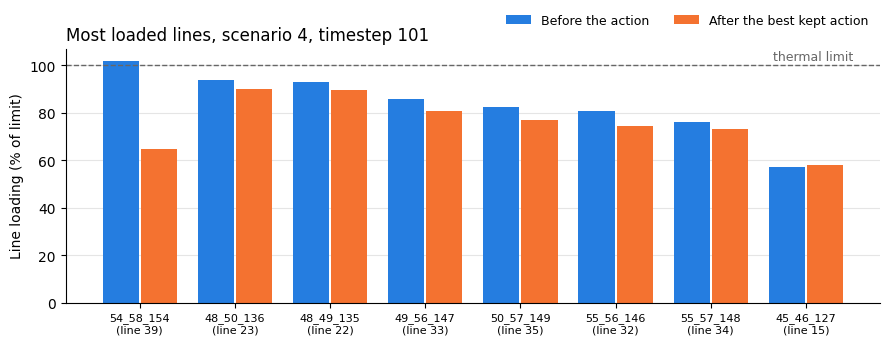

This action will:
	 - NOT change anything to the injections
	 - NOT perform any redispatching action
	 - NOT modify any storage capacity
	 - NOT perform any curtailment
	 - NOT force any line status
	 - NOT switch any line status
	 - NOT switch anything in the topology
	 - Set the bus of the following element(s):
	 	 - Assign bus 1 to line (extremity) id 36 [on substation 26]
	 	 - Assign bus 1 to line (extremity) id 37 [on substation 26]
	 	 - Assign bus 1 to line (extremity) id 38 [on substation 26]
	 	 - Assign bus 2 to line (extremity) id 39 [on substation 26]
	 	 - Assign bus 1 to line (origin) id 40 [on substation 26]
	 	 - Assign bus 1 to line (origin) id 41 [on substation 26]
	 	 - Assign bus 2 to line (extremity) id 56 [on substation 26]
	 	 - Assign bus 1 to generator id 14 [on substation 26]
	 	 - Assign bus 2 to load id 27 [on substation 26]
	 - Not raise any alarm


In [7]:
kept = expert_system_results.loc[action_indices]
best_index = kept.sort_values(["Topology simulated score", "Efficacity"], ascending=False).index[0]
best_action = actions[best_index]
obs_after, *_ = obs.simulate(best_action, time_step=0)

lines = np.argsort(-np.maximum(obs.rho, obs_after.rho))[:8]
x = np.arange(len(lines))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x - 0.2, obs.rho[lines] * 100, width=0.38, color="#257de0", label="Before the action")
ax.bar(x + 0.2, obs_after.rho[lines] * 100, width=0.38, color="#f47230", label="After the best kept action")
ax.axhline(100, color="#666666", linestyle="--", linewidth=1)
ax.text(len(lines) - 0.5, 101, "thermal limit", ha="right", va="bottom", color="#666666", fontsize=9)
ax.set_xticks(x, [f"{env.name_line[l]}\n(line {l})" for l in lines], fontsize=8)
ax.set_ylabel("Line loading (% of limit)")
ax.set_title(f"Most loaded lines, scenario {chronic}, timestep {timestep}", loc="left")
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 1.18), ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

print(best_action)

For convenience, the steps of sections 3 and 4 are gathered in one function. It is the same code as in the body of the scripts' loop, and it is reused in section 7.

In [8]:
def expert_analysis(obs, action_space, observation_space, config):
    # The overloaded lines, the simulated candidates with their scores, and the actions scoring >= 3.
    ltc = [int(l) for l in np.where(obs.rho > 1)[0]]
    with quiet():
        sim = Grid2opSimulation(obs, action_space, observation_space,
                                param_options=config["DEFAULT"], debug=False, ltc=ltc, plot=False)
        g_over = OverFlowGraph(sim.topo, ltc, sim.get_dataframe())
        simulator_data = {"substations_elements": sim.get_substation_elements(),
                          "substation_to_node_mapping": sim.get_substation_to_node_mapping(),
                          "internal_to_external_mapping": sim.get_internal_to_external_mapping()}
        alphadeesp = AlphaDeesp(g_over.get_graph(), sim.get_dataframe(), simulator_data, sim.substation_in_cooldown)
        alphadeesp.identify_routing_buses()
        ranked_combinations = alphadeesp.get_ranked_combinations()
        results, actions = sim.compute_new_network_changes(ranked_combinations)
    kept = [actions[i] for i in results[results["Topology simulated score"] >= 3].index]
    return ltc, results, kept

## 5. From the kept actions to the saved files

The scripts gather the kept actions of all the analysed states in `action_list`, **without duplicates**: the same topology often solves the overloads of many consecutive timesteps.

They also record the index of each action in the full action space, in `original_action_indices`. That index comes from grid2op's `IdToAct` converter, which lists every action. One topology can be written in two ways: putting elements A on bus 1 and B on bus 2 is the same as putting A on bus 2 and B on bus 1. The converter lists only one of the two, so when an action is not found, the scripts look for its **symmetry** (`action_symmetry`, which swaps buses 1 and 2).

In [9]:
with quiet():
    converter = IdToAct(env.action_space)
    converter.init_converter()
print(f"The full action space of {env_name} has {len(converter.all_actions):,} actions "
      f"(set_bus, line status, ...)")

kept_actions = [actions[i] for i in action_indices]
for act in kept_actions[:3]:
    if act in converter.all_actions:
        print("action found in the full action space at index", converter.all_actions.index(act))
    elif action_symmetry(act) in converter.all_actions:
        print("symmetric action found at index", converter.all_actions.index(action_symmetry(act)))
    else:
        print("action not found in the full action space")

The full action space of ai4realnet_small has 134,283 actions (set_bus, line status, ...)


symmetric action found at index 66203


action found in the full action space at index 66745


symmetric action found at index 66117


The list is then saved by `save_actions` (in [`helper_functions.py`](../ExpertAgent/utils/helper_functions.py)) in two forms:

- **Encoded strings in a `.csv`**: each `set_bus` action is compressed (zlib) and encoded in base64 by `EncodedTopologyAction`. This short string is easy to store and to compare.
- **Action vectors in a `.npz`**: the unique actions are decoded, and each one is turned into its grid2op vector (`action.to_vect()`). The array `action_space`, of shape (number of actions × action vector size), is what the agents load.

Encoding then decoding gives back the same action:

In [10]:
act = kept_actions[0]
encoded = EncodedTopologyAction.encode_action(act)
decoded = EncodedTopologyAction.decode_action(encoded, env)
print("encoded:", encoded)
print("decoded == original:", decoded == act)
print("vector size:", act.to_vect().shape, "(the size of a grid2op action of this environment)")

encoded: eAFjYBgFgzUEmIAOYwRiGA1ijwLMEAAACqwACA==
decoded == original: True
vector size: (519,) (the size of a grid2op action of this environment)


## 6. Running `get_expert_actions` on a few timesteps

`get_expert_actions` is the function of `extractExpertActions.py`, and it does everything above in a loop. By default it goes over every timestep of every scenario. Its optional arguments `chronic_indices` and `timesteps` limit it to a few, and `save_dir` chooses where the files are written. The default is `local_data/<env_name>/ExpertActions` (see [Pretrained models and `local_data`](../README.md#pretrained-models-and-local_data)).

> The scripts save the list after every analysed timestep, so that a long run can be stopped without losing everything. They **append** to the `.csv`, and compute the `.npz` from the unique rows of the whole `.csv`. A second run in the same folder therefore adds to the results of the first one. This notebook uses its own folder, emptied at each run.

In [11]:
demo_dir = os.path.join(get_local_data_dir(), env_name, "ExpertActions", "notebook_demo")
shutil.rmtree(demo_dir, ignore_errors=True)

with quiet():
    get_expert_actions(config, env_path, env_name,
                       chronic_indices=[chronic], timesteps=range(timestep, timestep + 5),
                       save_dir=demo_dir)

for f in sorted(os.listdir(demo_dir)):
    print(f)

result = np.load(os.path.join(demo_dir, f"{env_name}_expert_actions_vectorized_.npz"))
print(f"\n{result['action_space'].shape[0]} unique expert actions found on 5 timesteps of scenario {chronic}; "
      f"array shape {result['action_space'].shape}")

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:24<00:00, 24.46s/it]

100%|██████████| 1/1 [00:24<00:00, 24.46s/it]

ai4realnet_small_action_list_encoded_.csv
ai4realnet_small_expert_actions_vectorized_.npz

5 unique expert actions found on 5 timesteps of scenario 4; array shape (5, 519)


## 7. The attacking variant: overloads after a line disconnection

An agent must also cope with the grid after a line has been disconnected, whether by an attack (the opponent of the AI4REALNET environments) or by a contingency. Disconnecting a line pushes its flow onto the others, and overloads appear that never happen in normal operation. The nominal action list has no answer for them.

`extractAttackingExpertActions.py` runs the same analysis in a modified loop. For each line in `--disc_list`, at every timestep, it:

1. loads the state,
2. **disconnects the line** (`set_line_status = -1`) and makes one step,
3. runs the expert analysis if a line is now overloaded.

The default `disc_list` of the script holds the lines below.

In [12]:
default_disc_list = [45, 56, 0, 9, 13, 14, 18, 23, 27, 39]
print("Lines attacked by default:", ", ".join(f"{l} ({env.name_line[l]})" for l in default_disc_list))

attacked_line, a_chronic, a_timestep = 45, 0, 24
with quiet():
    env, obs, action_space = loader.get_observation(chronic_scenario=a_chronic, timestep=a_timestep)
rho_before = obs.rho.max()

new_line_status_array = np.zeros(obs.rho.shape, dtype=int)
new_line_status_array[attacked_line] = -1
obs, _, done, _ = env.step(env.action_space({"set_line_status": new_line_status_array}))

print(f"\nScenario {a_chronic}, timestep {a_timestep}: highest line loading {rho_before:.1%} before "
      f"disconnecting line {attacked_line}, {obs.rho.max():.1%} after")

ltc, results, kept = expert_analysis(obs, action_space, env.observation_space, config)
print(f"Overloaded lines after the disconnection: {ltc}")
print(f"{len(results)} candidates simulated, {len(kept)} kept (score >= 3)")

Lines attacked by default: 45 (62_63_160), 56 (62_58_180), 0 (34_35_110), 9 (39_41_121), 13 (43_44_125), 14 (44_45_126), 18 (41_48_131), 23 (48_50_136), 27 (48_53_141), 39 (54_58_154)



Scenario 0, timestep 24: highest line loading 88.3% before disconnecting line 45, 103.9% after


Overloaded lines after the disconnection: [32, 35]
30 candidates simulated, 6 kept (score >= 3)


The expert system does not always find a solution. Earlier in the same scenario (timesteps 12 to 21), disconnecting line 45 overloads three lines at once, and AlphaDeesp returns no candidate at all. Such states add nothing to the list.

In the script, each attacked line is handled by a separate process (`--jobs` of them in parallel). All the processes write to the same `<env>_..._attacking` files, so the `.npz` holds the actions found for all the attacked lines.

Here is `get_attacking_expert_actions`, on one attacked line and a few timesteps:

In [13]:
with quiet():
    get_attacking_expert_actions(config, env_path, env_name, [attacked_line],
                                 chronic_indices=[a_chronic], timesteps=range(a_timestep, a_timestep + 4),
                                 save_dir=demo_dir)

attacking = np.load(os.path.join(demo_dir, f"{env_name}_expert_actions_vectorized_attacking.npz"))
print(f"{attacking['action_space'].shape[0]} unique actions found after disconnecting line {attacked_line}, "
      f"on 4 timesteps of scenario {a_chronic}")

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:21<00:00, 21.89s/it]

100%|██████████| 1/1 [00:21<00:00, 21.89s/it]

6 unique actions found after disconnecting line 45, on 4 timesteps of scenario 0


## 8. How the agents use the extracted actions

To be used by an agent, an extracted `.npz` is copied into [`ExpertAgent/assets`](../ExpertAgent/assets), which is installed with the package (the `ASSETS` path). The files used by the agents of `ai4realnet_small`:

| File in `ExpertAgent/assets` | Actions | Used by |
|---|---|---|
| `ai4realnet_small_expert_actions_vector.npz` | 224 | `ExpertAgentHeuristic`, argument `action_space_expert`: actions tried first when the grid is in danger |
| `attacking_teacher_actionspace.npz` | 250 | `ExpertAgentHeuristic`, argument `action_space_unsafe` |
| `whole_action_space.npz` | 603 | `ExpertAgentRL`: the discrete action space of the PPO policy (`make_gymenv` in `helper_functions.py`) |

`whole_action_space.npz` is built with `combine_action_spaces` (in `helper_functions.py`). It stacks the nominal expert actions, the attacking actions kept with score 4, and the attacking teacher actions:

In [14]:
def load(name):
    return np.load(os.path.join(ASSETS, name))["action_space"]

parts = ["ai4realnet_small_expert_actions_vector.npz",
         "ai4realnet_small_expert_actions_vectorized_attacking_pool_score4.npz",
         "attacking_teacher_actionspace.npz"]
for name in parts:
    print(f"{load(name).shape[0]:4d}  {name}")

whole = load("whole_action_space.npz")
print(f"{whole.shape[0]:4d}  whole_action_space.npz")
print("\nwhole_action_space.npz == the three files stacked in this order:",
      np.array_equal(whole, np.vstack([load(name) for name in parts])))
print(f"Actions present in more than one file: {whole.shape[0] - len(np.unique(whole, axis=0))}")

 224  ai4realnet_small_expert_actions_vector.npz
 129  ai4realnet_small_expert_actions_vectorized_attacking_pool_score4.npz
 250  attacking_teacher_actionspace.npz
 603  whole_action_space.npz

whole_action_space.npz == the three files stacked in this order: True
Actions present in more than one file: 70


> `combine_action_spaces` writes its result into `ExpertAgent/assets/whole_action_space.npz` and replaces the file there. It is not run in this notebook. To change the action space of the RL agent, combine the new files on purpose, then train the agent again: the PPO policy has one output per action.

Which substations do the 224 nominal expert actions act on? The expert system concentrates them on the few substations where a change of topology relieves overloads:

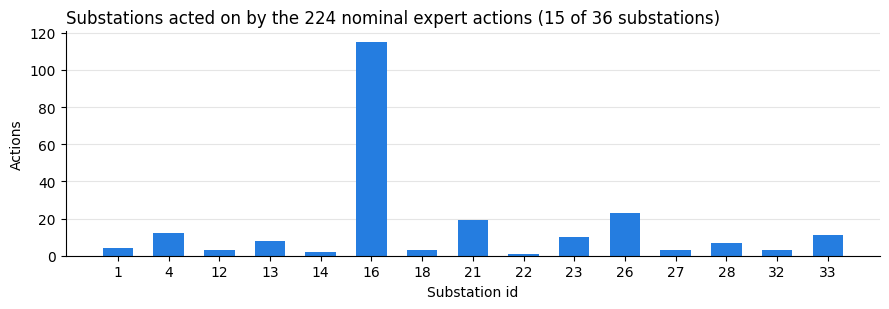

In [15]:
expert_actions = [env.action_space.from_vect(v) for v in load("ai4realnet_small_expert_actions_vector.npz")]
subs = pd.Series([int(s) for a in expert_actions for s in a.as_dict().get("set_bus_vect", {}).get("modif_subs_id", [])])
counts = subs.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar([str(s) for s in counts.index], counts.values, width=0.6, color="#257de0")
ax.set_xlabel("Substation id")
ax.set_ylabel("Actions")
ax.set_title(f"Substations acted on by the {len(expert_actions)} nominal expert actions "
             f"({counts.size} of {env.n_sub} substations)", loc="left")
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 9. Running the full extraction from the command line

From the root of the repository, with the environment in `~/data_grid2op/<environment>`:

```bash
# expert actions in normal operation
python ExpertAgent/utils/extractExpertActions.py --environment=ai4realnet_small

# expert actions after disconnecting each line of the list, one process per line
python ExpertAgent/utils/extractAttackingExpertActions.py --environment=ai4realnet_small \
    --disc_list="[45, 56, 0, 9, 13, 14, 18, 23, 27, 39]" --jobs=10
```

- The results go to `local_data/<environment>/ExpertActions/`:
  - nominal: `<env>_action_list_encoded_.csv` and `<env>_expert_actions_vectorized_.npz`
  - attacking: the same names ending with `attacking`
- The progress is logged in `expert.log` and `attacking_expert.log`, in the folder the script is started from.
- To use a result in an agent, copy the `.npz` into `ExpertAgent/assets` (section 8). If the agent is a learning one, train it again.